# Fairness-Aware Credit Risk Prediction using the German Credit Dataset<a href="#Fairness-Aware-Credit-Risk-Prediction-using-the-German-Credit-Dataset" class="anchor-link">¶</a>

## M515 Ethical Issues for AI<a href="#M515-Ethical-Issues-for-AI" class="anchor-link">¶</a>

### Individual Project<a href="#Individual-Project" class="anchor-link">¶</a>

**Student Name:** Dhakshitha Mohan Rao

**Student ID:** GH1044699

**Module:** M515 Ethical Issues for AI

**Dataset:** German Credit Dataset

**Dataset Source:** <https://archive.ics.uci.edu/ml/datasets/statlog+(german+credit+data>)

------------------------------------------------------------------------

# 1. Introduction<a href="#1.-Introduction" class="anchor-link">¶</a>

Artificial Intelligence (AI) and Machine Learning (ML) systems are increasingly being adopted in financial institutions to automate decision-making processes such as credit approval. While these systems improve efficiency and consistency, they may also inherit and amplify existing societal biases present in historical data. Consequently, ensuring fairness and unbiased decision-making has become a critical requirement in the development of responsible AI systems.

This project investigates fairness in automated credit scoring using the German Credit dataset. A machine learning model will be developed to predict whether a loan applicant represents a good or bad credit risk. The fairness of the model will then be evaluated with respect to a protected attribute, and a fairness mitigation technique will be applied to reduce potential bias and improve equitable decision-making.

# 2. Problem Statement<a href="#2.-Problem-Statement" class="anchor-link">¶</a>

## Underlying Business Problem<a href="#Underlying-Business-Problem" class="anchor-link">¶</a>

Financial institutions process a large number of loan applications every year. Traditionally, loan approval decisions have been made by credit officers based on applicants' financial and personal information. However, manual evaluation is time-consuming, expensive, and susceptible to inconsistencies and human biases. To improve efficiency and consistency, banks increasingly use machine learning models to automate credit risk assessment.

The objective of this project is to build a machine learning model that classifies loan applicants as either good or bad credit risks based on patterns learned from historical data in the German Credit dataset.

## Importance of the Problem<a href="#Importance-of-the-Problem" class="anchor-link">¶</a>

Accurate assessment of credit risk is crucial for banks, as inaccurate lending decisions can lead to substantial financial implications. Granting loans to applicants with a high likelihood of default can increase financial losses and raise default rates. On the other hand, denying loans to reliable borrowers may lead to missed business opportunities and lower customer satisfaction.

Furthermore, loan approval decisions directly affect individuals' access to financial resources, making the problem socially and economically important.

## Benefits to the Company<a href="#Benefits-to-the-Company" class="anchor-link">¶</a>

Developing an accurate credit risk prediction model provides several benefits to financial institutions:

- Reduces financial losses caused by loan defaults.
- Improves operational efficiency by automating the decision-making process.
- Enables faster processing of loan applications.
- Ensures more consistent and objective lending decisions.
- Enhances customer satisfaction by reducing decision time.

## Data Collection<a href="#Data-Collection" class="anchor-link">¶</a>

The data required for this problem can be collected from various sources, including customer loan application forms, credit bureau reports, banking transaction records, employment information, and historical loan repayment records.

The German Credit dataset contains information about applicants, including attributes such as credit history, loan amount, employment duration, savings status, personal characteristics, and age. These features are used to evaluate the creditworthiness of loan applicants.

## Machine Learning Formulation<a href="#Machine-Learning-Formulation" class="anchor-link">¶</a>

The problem can be formulated as a supervised machine learning task, specifically a binary classification problem. Given a set of applicant characteristics, the model predicts whether an individual should be classified as a good credit risk or a bad credit risk.

The input variables consist of applicant attributes, while the target variable represents the applicant's creditworthiness. The objective is to train a model that accurately predicts the target class for new loan applicants.

# 3. Ethical Concerns<a href="#3.-Ethical-Concerns" class="anchor-link">¶</a>

The use of machine learning in credit scoring raises several ethical concerns because lending decisions have a significant impact on individuals' financial well-being and quality of life. Access to credit can influence a person's ability to purchase a home, pursue higher education, start a business, or manage unexpected financial expenses. Therefore, it is essential that automated decision-making systems operate fairly and do not discriminate against particular groups of people.

One major ethical concern is that machine learning models learn patterns from historical data. If historical lending decisions contain societal or institutional biases, the model may inherit and reinforce these biases. As a result, certain demographic groups may systematically receive less favorable outcomes, even when they have similar financial characteristics to other applicants.

In the German Credit dataset, age may potentially lead to discriminatory outcomes. Younger applicants may be disadvantaged if the model associates age with higher credit risk. Such discrimination can result in unfair denial of loans to qualified individuals.

To investigate potential unfairness, this project considers age as the protected attribute. Applicants aged 25 years and above are treated as the privileged group, while applicants below 25 years are considered the unprivileged group. The fairness of the model will be evaluated by comparing prediction outcomes across these groups using established fairness metrics.

Ensuring fairness in credit scoring systems is particularly important because biased lending decisions can have serious social, ethical, and legal implications. Fair and unbiased decision-making promotes equal access to financial services, increases transparency, strengthens public trust in artificial intelligence systems, and supports responsible AI practices within the financial sector.

In \[ \]:

<span class="kn">import</span><span class="w"> </span><span class="nn">pandas</span><span class="w"> </span><span class="k">as</span><span class="w"> </span><span class="nn">pd</span>  
<span class="kn">import</span><span class="w"> </span><span class="nn">numpy</span><span class="w"> </span><span class="k">as</span><span class="w"> </span><span class="nn">np</span>  
<span class="kn">import</span><span class="w"> </span><span class="nn">matplotlib.pyplot</span><span class="w"> </span><span class="k">as</span><span class="w"> </span><span class="nn">plt</span>  
<span class="kn">import</span><span class="w"> </span><span class="nn">seaborn</span><span class="w"> </span><span class="k">as</span><span class="w"> </span><span class="nn">sns</span>  
  
<span class="kn">from</span><span class="w"> </span><span class="nn">sklearn.model_selection</span><span class="w"> </span><span class="kn">import</span> <span class="n">train_test_split</span>  
<span class="kn">from</span><span class="w"> </span><span class="nn">sklearn.preprocessing</span><span class="w"> </span><span class="kn">import</span> <span class="n">LabelEncoder</span>  
  
<span class="o">%</span><span class="n">matplotlib</span> <span class="n">inline</span>  

# 4. Dataset Description and Exploratory Data Analysis<a href="#4.-Dataset-Description-and-Exploratory-Data-Analysis" class="anchor-link">¶</a>

The German Credit dataset comprises data on 1,000 loan applicants, represented by 20 features such as credit history, employment status, loan amount, savings, age, and other personal and financial characteristics. The main objective is to classify applicants as either good or bad credit risks. To support model development, Exploratory Data Analysis (EDA) is conducted to examine the dataset's structure, detect potential data quality problems, and explore the distribution and relationships of key variables.

In \[ \]:

<span class="n">columns</span> <span class="o">=</span> <span class="p">\[</span>  
    <span class="s1">'status'</span><span class="p">,</span> <span class="s1">'duration'</span><span class="p">,</span> <span class="s1">'credit_history'</span><span class="p">,</span> <span class="s1">'purpose'</span><span class="p">,</span>  
    <span class="s1">'credit_amount'</span><span class="p">,</span> <span class="s1">'savings'</span><span class="p">,</span> <span class="s1">'employment_duration'</span><span class="p">,</span>  
    <span class="s1">'installment_rate'</span><span class="p">,</span> <span class="s1">'personal_status_sex'</span><span class="p">,</span> <span class="s1">'other_debtors'</span><span class="p">,</span>  
    <span class="s1">'residence_since'</span><span class="p">,</span> <span class="s1">'property'</span><span class="p">,</span> <span class="s1">'age'</span><span class="p">,</span>  
    <span class="s1">'other_installment_plans'</span><span class="p">,</span> <span class="s1">'housing'</span><span class="p">,</span>  
    <span class="s1">'existing_credits'</span><span class="p">,</span> <span class="s1">'job'</span><span class="p">,</span> <span class="s1">'people_liable'</span><span class="p">,</span>  
    <span class="s1">'telephone'</span><span class="p">,</span> <span class="s1">'foreign_worker'</span><span class="p">,</span> <span class="s1">'target'</span>  
<span class="p">\]</span>  
  
<span class="n">df</span> <span class="o">=</span> <span class="n">pd</span><span class="o">.</span><span class="n">read_csv</span><span class="p">(</span>  
    <span class="s1">'german.data'</span><span class="p">,</span>  
    <span class="n">sep</span><span class="o">=</span><span class="s1">' '</span><span class="p">,</span>  
    <span class="n">header</span><span class="o">=</span><span class="kc">None</span><span class="p">,</span>  
    <span class="n">names</span><span class="o">=</span><span class="n">columns</span>  
<span class="p">)</span>  
  
<span class="n">df</span><span class="o">.</span><span class="n">head</span><span class="p">()</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|  | status | duration | credit_history | purpose | credit_amount | savings | employment_duration | installment_rate | personal_status_sex | other_debtors | ... | property | age | other_installment_plans | housing | existing_credits | job | people_liable | telephone | foreign_worker | target |
|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|
| 0 | A11 | 6 | A34 | A43 | 1169 | A65 | A75 | 4 | A93 | A101 | ... | A121 | 67 | A143 | A152 | 2 | A173 | 1 | A192 | A201 | 1 |
| 1 | A12 | 48 | A32 | A43 | 5951 | A61 | A73 | 2 | A92 | A101 | ... | A121 | 22 | A143 | A152 | 1 | A173 | 1 | A191 | A201 | 2 |
| 2 | A14 | 12 | A34 | A46 | 2096 | A61 | A74 | 2 | A93 | A101 | ... | A121 | 49 | A143 | A152 | 1 | A172 | 2 | A191 | A201 | 1 |
| 3 | A11 | 42 | A32 | A42 | 7882 | A61 | A74 | 2 | A93 | A103 | ... | A122 | 45 | A143 | A153 | 1 | A173 | 2 | A191 | A201 | 1 |
| 4 | A11 | 24 | A33 | A40 | 4870 | A61 | A73 | 3 | A93 | A101 | ... | A124 | 53 | A143 | A153 | 2 | A173 | 2 | A191 | A201 | 2 |

5 rows × 21 columns



<style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

In \[ \]:

<span class="nb">print</span><span class="p">(</span><span class="s2">"Dataset Shape:"</span><span class="p">,</span> <span class="n">df</span><span class="o">.</span><span class="n">shape</span><span class="p">)</span>  
<span class="nb">print</span><span class="p">(</span><span class="s2">"</span><span class="se">\n</span><span class="s2">"</span><span class="p">)</span>  
  
<span class="n">df</span><span class="o">.</span><span class="n">info</span><span class="p">()</span>  

Dataset Shape: (1000, 21)  
  
  
\<class 'pandas.core.frame.DataFrame'\>  
RangeIndex: 1000 entries, 0 to 999  
Data columns (total 21 columns):  
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   status                   1000 non-null   object  
 1   duration                 1000 non-null   int64   
 2   credit_history           1000 non-null   object  
 3   purpose                  1000 non-null   object  
 4   credit_amount            1000 non-null   int64   
 5   savings                  1000 non-null   object  
 6   employment_duration      1000 non-null   object  
 7   installment_rate         1000 non-null   int64   
 8   personal_status_sex      1000 non-null   object  
 9   other_debtors            1000 non-null   object  
 10  residence_since          1000 non-null   int64   
 11  property                 1000 non-null   object  
 12  age                      1000 non-null   int64   
 13  other_installment_plans  1000 non-null   object  
 14  housing                  1000 non-null   object  
 15  existing_credits         1000 non-null   int64   
 16  job                      1000 non-null   object  
 17  people_liable            1000 non-null   int64   
 18  telephone                1000 non-null   object  
 19  foreign_worker           1000 non-null   object  
 20  target                   1000 non-null   int64   
dtypes: int64(8), object(13)  
memory usage: 164.2+ KB  

In \[ \]:

<span class="n">df</span><span class="o">.</span><span class="n">isnull</span><span class="p">()</span><span class="o">.</span><span class="n">sum</span><span class="p">()</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|                         | 0   |
|-------------------------|-----|
| status                  | 0   |
| duration                | 0   |
| credit_history          | 0   |
| purpose                 | 0   |
| credit_amount           | 0   |
| savings                 | 0   |
| employment_duration     | 0   |
| installment_rate        | 0   |
| personal_status_sex     | 0   |
| other_debtors           | 0   |
| residence_since         | 0   |
| property                | 0   |
| age                     | 0   |
| other_installment_plans | 0   |
| housing                 | 0   |
| existing_credits        | 0   |
| job                     | 0   |
| people_liable           | 0   |
| telephone               | 0   |
| foreign_worker          | 0   |
| target                  | 0   |

  
**dtype:** int64

In \[ \]:

<span class="n">df</span><span class="o">.</span><span class="n">describe</span><span class="p">()</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|  | duration | credit_amount | installment_rate | residence_since | age | existing_credits | people_liable | target |
|----|----|----|----|----|----|----|----|----|
| count | 1000.000000 | 1000.000000 | 1000.000000 | 1000.000000 | 1000.000000 | 1000.000000 | 1000.000000 | 1000.000000 |
| mean | 20.903000 | 3271.258000 | 2.973000 | 2.845000 | 35.546000 | 1.407000 | 1.155000 | 1.300000 |
| std | 12.058814 | 2822.736876 | 1.118715 | 1.103718 | 11.375469 | 0.577654 | 0.362086 | 0.458487 |
| min | 4.000000 | 250.000000 | 1.000000 | 1.000000 | 19.000000 | 1.000000 | 1.000000 | 1.000000 |
| 25% | 12.000000 | 1365.500000 | 2.000000 | 2.000000 | 27.000000 | 1.000000 | 1.000000 | 1.000000 |
| 50% | 18.000000 | 2319.500000 | 3.000000 | 3.000000 | 33.000000 | 1.000000 | 1.000000 | 1.000000 |
| 75% | 24.000000 | 3972.250000 | 4.000000 | 4.000000 | 42.000000 | 2.000000 | 1.000000 | 2.000000 |
| max | 72.000000 | 18424.000000 | 4.000000 | 4.000000 | 75.000000 | 4.000000 | 2.000000 | 2.000000 |



<style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

In \[ \]:

<span class="n">df</span><span class="o">.</span><span class="n">head</span><span class="p">()</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|  | status | duration | credit_history | purpose | credit_amount | savings | employment_duration | installment_rate | personal_status_sex | other_debtors | ... | property | age | other_installment_plans | housing | existing_credits | job | people_liable | telephone | foreign_worker | target |
|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|
| 0 | A11 | 6 | A34 | A43 | 1169 | A65 | A75 | 4 | A93 | A101 | ... | A121 | 67 | A143 | A152 | 2 | A173 | 1 | A192 | A201 | 1 |
| 1 | A12 | 48 | A32 | A43 | 5951 | A61 | A73 | 2 | A92 | A101 | ... | A121 | 22 | A143 | A152 | 1 | A173 | 1 | A191 | A201 | 2 |
| 2 | A14 | 12 | A34 | A46 | 2096 | A61 | A74 | 2 | A93 | A101 | ... | A121 | 49 | A143 | A152 | 1 | A172 | 2 | A191 | A201 | 1 |
| 3 | A11 | 42 | A32 | A42 | 7882 | A61 | A74 | 2 | A93 | A103 | ... | A122 | 45 | A143 | A153 | 1 | A173 | 2 | A191 | A201 | 1 |
| 4 | A11 | 24 | A33 | A40 | 4870 | A61 | A73 | 3 | A93 | A101 | ... | A124 | 53 | A143 | A153 | 2 | A173 | 2 | A191 | A201 | 2 |

5 rows × 21 columns



<style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

### Initial Findings<a href="#Initial-Findings" class="anchor-link">¶</a>

The German Credit dataset contains 1,000 observations and 21 attributes. The dataset consists of both categorical and numerical variables describing the financial and personal characteristics of loan applicants.

An initial inspection shows that the dataset does not contain missing values, which simplifies the preprocessing stage. The presence of both numerical and categorical attributes indicates that appropriate preprocessing techniques, such as encoding categorical variables, will be required before model training.

Understanding the structure and characteristics of the dataset is essential for building a reliable and fair machine learning model.

## Visual Exploratory Data Analysis<a href="#Visual-Exploratory-Data-Analysis" class="anchor-link">¶</a>

Visualizing the dataset helps in understanding the distribution of important variables and identifying patterns that may influence model predictions. Since fairness is a central focus of this project, particular attention is given to the distribution of age, as it is considered the protected attribute in this study.

In \[ \]:

<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">6</span><span class="p">,</span><span class="mi">4</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">countplot</span><span class="p">(</span><span class="n">x</span><span class="o">=</span><span class="s1">'target'</span><span class="p">,</span> <span class="n">data</span><span class="o">=</span><span class="n">df</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Distribution of Credit Risk'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xlabel</span><span class="p">(</span><span class="s1">'Credit Risk (1 = Good, 2 = Bad)'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Number of Applicants'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](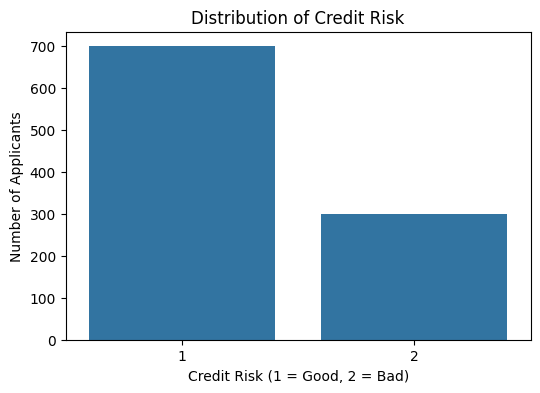%0A)

In \[ \]:

<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">8</span><span class="p">,</span><span class="mi">5</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">histplot</span><span class="p">(</span><span class="n">df</span><span class="p">\[</span><span class="s1">'age'</span><span class="p">\],</span> <span class="n">bins</span><span class="o">=</span><span class="mi">20</span><span class="p">,</span> <span class="n">kde</span><span class="o">=</span><span class="kc">True</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Distribution of Applicant Age'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xlabel</span><span class="p">(</span><span class="s1">'Age'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Frequency'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](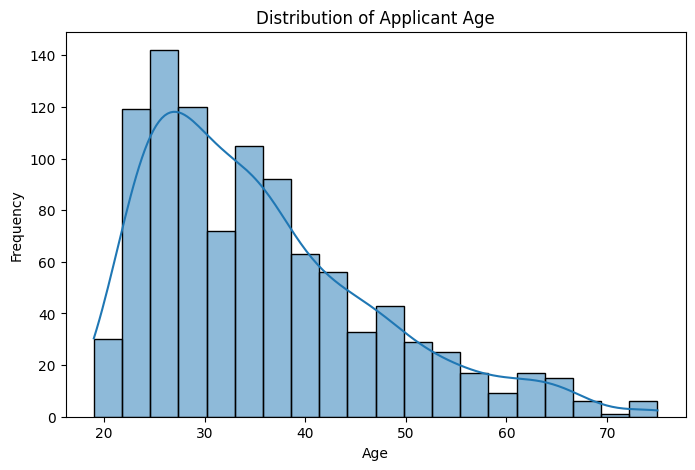%0A)

In \[ \]:

<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">8</span><span class="p">,</span><span class="mi">5</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">histplot</span><span class="p">(</span><span class="n">df</span><span class="p">\[</span><span class="s1">'credit_amount'</span><span class="p">\],</span> <span class="n">bins</span><span class="o">=</span><span class="mi">30</span><span class="p">,</span> <span class="n">kde</span><span class="o">=</span><span class="kc">True</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Distribution of Credit Amount'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xlabel</span><span class="p">(</span><span class="s1">'Credit Amount'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Frequency'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](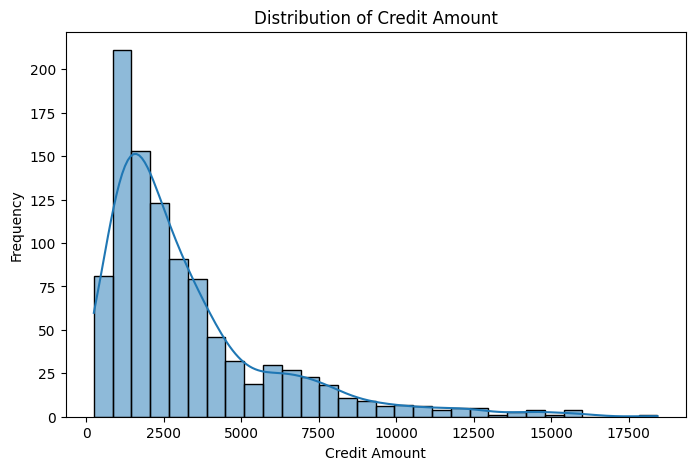%0A)

In \[ \]:

<span class="n">df</span><span class="p">\[</span><span class="s1">'age_group'</span><span class="p">\]</span> <span class="o">=</span> <span class="n">np</span><span class="o">.</span><span class="n">where</span><span class="p">(</span><span class="n">df</span><span class="p">\[</span><span class="s1">'age'</span><span class="p">\]</span> <span class="o">\>=</span> <span class="mi">25</span><span class="p">,</span>  
                           <span class="s1">'Privileged (\>=25)'</span><span class="p">,</span>  
                           <span class="s1">'Unprivileged (\<25)'</span><span class="p">)</span>  
  
<span class="n">df</span><span class="p">\[\[</span><span class="s1">'age'</span><span class="p">,</span> <span class="s1">'age_group'</span><span class="p">\]\]</span><span class="o">.</span><span class="n">head</span><span class="p">()</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|     | age | age_group           |
|-----|-----|---------------------|
| 0   | 67  | Privileged (\>=25)  |
| 1   | 22  | Unprivileged (\<25) |
| 2   | 49  | Privileged (\>=25)  |
| 3   | 45  | Privileged (\>=25)  |
| 4   | 53  | Privileged (\>=25)  |



<style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

In \[ \]:

<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">6</span><span class="p">,</span><span class="mi">4</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">countplot</span><span class="p">(</span><span class="n">x</span><span class="o">=</span><span class="s1">'age_group'</span><span class="p">,</span> <span class="n">data</span><span class="o">=</span><span class="n">df</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Distribution of Age Groups'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xlabel</span><span class="p">(</span><span class="s1">'Age Group'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Number of Applicants'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">xticks</span><span class="p">(</span><span class="n">rotation</span><span class="o">=</span><span class="mi">10</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](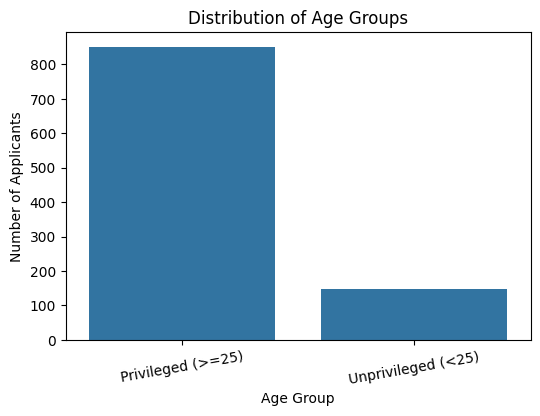%0A)

In \[ \]:

<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">7</span><span class="p">,</span><span class="mi">5</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">countplot</span><span class="p">(</span><span class="n">x</span><span class="o">=</span><span class="s1">'age_group'</span><span class="p">,</span>  
              <span class="n">hue</span><span class="o">=</span><span class="s1">'target'</span><span class="p">,</span>  
              <span class="n">data</span><span class="o">=</span><span class="n">df</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Credit Risk by Age Group'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xlabel</span><span class="p">(</span><span class="s1">'Age Group'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Number of Applicants'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">legend</span><span class="p">(</span><span class="n">title</span><span class="o">=</span><span class="s1">'Credit Risk'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](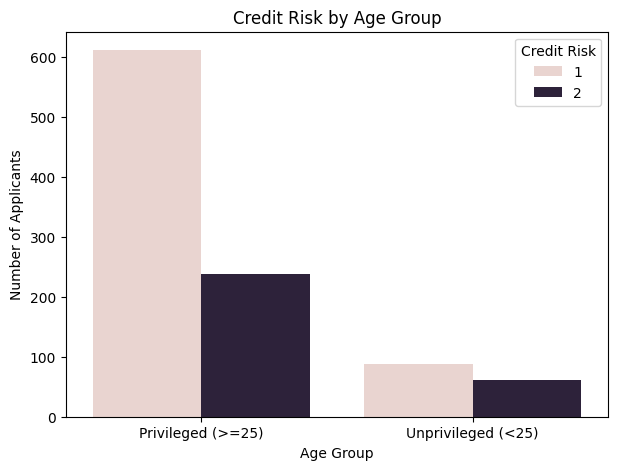%0A)

### Findings from Visual Exploratory Data Analysis<a href="#Findings-from-Visual-Exploratory-Data-Analysis" class="anchor-link">¶</a>

The target variable distribution indicates that the dataset contains more good credit applicants than bad credit applicants, suggesting a moderate class imbalance. The age distribution shows that most applicants are between 20 and 50 years old.

The analysis of age groups reveals that applicants aged 25 years and above constitute the majority of the dataset, while younger applicants represent a smaller proportion. Since age is considered the protected attribute, this imbalance may influence model behaviour and potentially lead to unfair outcomes.

The relationship between age groups and credit risk suggests that prediction outcomes may differ across demographic groups. Therefore, fairness assessment is necessary to ensure that the machine learning model does not systematically disadvantage younger applicants.

# 5. Data Preprocessing<a href="#5.-Data-Preprocessing" class="anchor-link">¶</a>

Prior to training the machine learning model, the dataset must undergo preprocessing to make it appropriate for analysis. The German Credit dataset includes both categorical and numerical features, and because machine learning algorithms operate on numerical data, all categorical variables need to be converted into numerical representations.

Furthermore, the target variable is transformed into a binary form, with good credit risk applicants assigned a value of 1 and bad credit risk applicants assigned a value of 0. The dataset is subsequently split into training and testing sets to assess the model's ability to generalize to unseen data.

In \[ \]:

<span class="n">df</span><span class="p">\[</span><span class="s1">'target'</span><span class="p">\]</span> <span class="o">=</span> <span class="n">df</span><span class="p">\[</span><span class="s1">'target'</span><span class="p">\]</span><span class="o">.</span><span class="n">replace</span><span class="p">({</span><span class="mi">1</span><span class="p">:</span> <span class="mi">1</span><span class="p">,</span> <span class="mi">2</span><span class="p">:</span> <span class="mi">0</span><span class="p">})</span>  
  
<span class="n">df</span><span class="p">\[</span><span class="s1">'target'</span><span class="p">\]</span><span class="o">.</span><span class="n">value_counts</span><span class="p">()</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|        | count |
|--------|-------|
| target |       |
| 1      | 700   |
| 0      | 300   |

  
**dtype:** int64

In \[ \]:

<span class="c1"># Create a copy of the dataset</span>  
  
<span class="n">df_encoded</span> <span class="o">=</span> <span class="n">df</span><span class="o">.</span><span class="n">copy</span><span class="p">()</span>  
  
<span class="c1"># Initialize Label Encoder</span>  
  
<span class="n">le</span> <span class="o">=</span> <span class="n">LabelEncoder</span><span class="p">()</span>  
  
<span class="c1"># Encode all categorical columns</span>  
  
<span class="k">for</span> <span class="n">column</span> <span class="ow">in</span> <span class="n">df_encoded</span><span class="o">.</span><span class="n">columns</span><span class="p">:</span>  
    <span class="k">if</span> <span class="n">df_encoded</span><span class="p">\[</span><span class="n">column</span><span class="p">\]</span><span class="o">.</span><span class="n">dtype</span> <span class="o">==</span> <span class="s1">'object'</span><span class="p">:</span>  
        <span class="n">df_encoded</span><span class="p">\[</span><span class="n">column</span><span class="p">\]</span> <span class="o">=</span> <span class="n">le</span><span class="o">.</span><span class="n">fit_transform</span><span class="p">(</span><span class="n">df_encoded</span><span class="p">\[</span><span class="n">column</span><span class="p">\])</span>  
  
<span class="n">df_encoded</span><span class="o">.</span><span class="n">head</span><span class="p">()</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|  | status | duration | credit_history | purpose | credit_amount | savings | employment_duration | installment_rate | personal_status_sex | other_debtors | ... | age | other_installment_plans | housing | existing_credits | job | people_liable | telephone | foreign_worker | target | age_group |
|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|----|
| 0 | 0 | 6 | 4 | 4 | 1169 | 4 | 4 | 4 | 2 | 0 | ... | 67 | 2 | 1 | 2 | 2 | 1 | 1 | 0 | 1 | 0 |
| 1 | 1 | 48 | 2 | 4 | 5951 | 0 | 2 | 2 | 1 | 0 | ... | 22 | 2 | 1 | 1 | 2 | 1 | 0 | 0 | 0 | 1 |
| 2 | 3 | 12 | 4 | 7 | 2096 | 0 | 3 | 2 | 2 | 0 | ... | 49 | 2 | 1 | 1 | 1 | 2 | 0 | 0 | 1 | 0 |
| 3 | 0 | 42 | 2 | 3 | 7882 | 0 | 3 | 2 | 2 | 2 | ... | 45 | 2 | 2 | 1 | 2 | 2 | 0 | 0 | 1 | 0 |
| 4 | 0 | 24 | 3 | 0 | 4870 | 0 | 2 | 3 | 2 | 0 | ... | 53 | 2 | 2 | 2 | 2 | 2 | 0 | 0 | 0 | 0 |

5 rows × 22 columns



<style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

In \[ \]:

<span class="n">X</span> <span class="o">=</span> <span class="n">df_encoded</span><span class="o">.</span><span class="n">drop</span><span class="p">(</span><span class="s1">'target'</span><span class="p">,</span> <span class="n">axis</span><span class="o">=</span><span class="mi">1</span><span class="p">)</span>  
  
<span class="n">y</span> <span class="o">=</span> <span class="n">df_encoded</span><span class="p">\[</span><span class="s1">'target'</span><span class="p">\]</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Feature Matrix Shape:"</span><span class="p">,</span> <span class="n">X</span><span class="o">.</span><span class="n">shape</span><span class="p">)</span>  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Target Vector Shape:"</span><span class="p">,</span> <span class="n">y</span><span class="o">.</span><span class="n">shape</span><span class="p">)</span>  

Feature Matrix Shape: (1000, 21)  
Target Vector Shape: (1000,)  

In \[ \]:

<span class="n">X_train</span><span class="p">,</span> <span class="n">X_test</span><span class="p">,</span> <span class="n">y_train</span><span class="p">,</span> <span class="n">y_test</span> <span class="o">=</span> <span class="n">train_test_split</span><span class="p">(</span>  
    <span class="n">X</span><span class="p">,</span>  
    <span class="n">y</span><span class="p">,</span>  
    <span class="n">test_size</span><span class="o">=</span><span class="mf">0.2</span><span class="p">,</span>  
    <span class="n">random_state</span><span class="o">=</span><span class="mi">42</span><span class="p">,</span>  
    <span class="n">stratify</span><span class="o">=</span><span class="n">y</span>  
<span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Training Set Shape:"</span><span class="p">,</span> <span class="n">X_train</span><span class="o">.</span><span class="n">shape</span><span class="p">)</span>  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Testing Set Shape:"</span><span class="p">,</span> <span class="n">X_test</span><span class="o">.</span><span class="n">shape</span><span class="p">)</span>  

Training Set Shape: (800, 21)  
Testing Set Shape: (200, 21)  

### Findings from Data Preprocessing<a href="#Findings-from-Data-Preprocessing" class="anchor-link">¶</a>

The target variable was converted into a binary representation to support the classification task. In addition, all categorical features were transformed into numerical form using Label Encoding, allowing machine learning algorithms to process the data efficiently.

The dataset was then split into training and testing subsets with an 80:20 ratio. The training data was used to build the machine learning model, whereas the testing data was retained to assess the model's performance on previously unseen samples.

Effective preprocessing is essential to ensure that the model learns meaningful patterns from the data while preserving consistency throughout the analytical process.

# 6. Baseline Machine Learning Model<a href="#6.-Baseline-Machine-Learning-Model" class="anchor-link">¶</a>

A baseline machine learning model is developed to predict the creditworthiness of loan applicants. Establishing a baseline model is important because it provides a reference point for evaluating both predictive performance and fairness.

In this project, a Random Forest Classifier is selected as the baseline model due to its robustness, ability to handle mixed data types, and strong predictive performance in classification tasks. The model is initially trained without applying any fairness intervention in order to assess whether discriminatory patterns exist in its predictions.

In \[ \]:

<span class="kn">from</span><span class="w"> </span><span class="nn">sklearn.ensemble</span><span class="w"> </span><span class="kn">import</span> <span class="n">RandomForestClassifier</span>  
  
<span class="c1"># Initialize the model</span>  
  
<span class="n">rf_model</span> <span class="o">=</span> <span class="n">RandomForestClassifier</span><span class="p">(</span>  
    <span class="n">n_estimators</span><span class="o">=</span><span class="mi">100</span><span class="p">,</span>  
    <span class="n">random_state</span><span class="o">=</span><span class="mi">42</span>  
<span class="p">)</span>  
  
<span class="c1"># Train the model</span>  
  
<span class="n">rf_model</span><span class="o">.</span><span class="n">fit</span><span class="p">(</span><span class="n">X_train</span><span class="p">,</span> <span class="n">y_train</span><span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Model training completed successfully."</span><span class="p">)</span>  

Model training completed successfully.  

In \[ \]:

<span class="n">y_pred</span> <span class="o">=</span> <span class="n">rf_model</span><span class="o">.</span><span class="n">predict</span><span class="p">(</span><span class="n">X_test</span><span class="p">)</span>  
  
<span class="n">y_pred</span><span class="p">\[:</span><span class="mi">10</span><span class="p">\]</span>  

Out\[ \]:

array(\[1, 0, 1, 1, 1, 1, 1, 1, 0, 1\])

In \[ \]:

<span class="kn">from</span><span class="w"> </span><span class="nn">sklearn.metrics</span><span class="w"> </span><span class="kn">import</span> <span class="n">accuracy_score</span>  
  
<span class="n">accuracy</span> <span class="o">=</span> <span class="n">accuracy_score</span><span class="p">(</span><span class="n">y_test</span><span class="p">,</span> <span class="n">y_pred</span><span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="sa">f</span><span class="s2">"Baseline Model Accuracy: </span><span class="si">{</span><span class="n">accuracy</span><span class="si">:</span><span class="s2">.4f</span><span class="si">}</span><span class="s2">"</span><span class="p">)</span>  

Baseline Model Accuracy: 0.7800  

In \[ \]:

<span class="kn">from</span><span class="w"> </span><span class="nn">sklearn.metrics</span><span class="w"> </span><span class="kn">import</span> <span class="n">classification_report</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="n">classification_report</span><span class="p">(</span><span class="n">y_test</span><span class="p">,</span> <span class="n">y_pred</span><span class="p">))</span>  

              precision    recall  f1-score   support  
  
           0       0.67      0.52      0.58        60  
           1       0.81      0.89      0.85       140  
  
    accuracy                           0.78       200  
   macro avg       0.74      0.70      0.72       200  
weighted avg       0.77      0.78      0.77       200  
  

In \[ \]:

<span class="kn">from</span><span class="w"> </span><span class="nn">sklearn.metrics</span><span class="w"> </span><span class="kn">import</span> <span class="n">confusion_matrix</span>  
  
<span class="n">cm</span> <span class="o">=</span> <span class="n">confusion_matrix</span><span class="p">(</span><span class="n">y_test</span><span class="p">,</span> <span class="n">y_pred</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">6</span><span class="p">,</span><span class="mi">5</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">heatmap</span><span class="p">(</span><span class="n">cm</span><span class="p">,</span>  
            <span class="n">annot</span><span class="o">=</span><span class="kc">True</span><span class="p">,</span>  
            <span class="n">fmt</span><span class="o">=</span><span class="s1">'d'</span><span class="p">,</span>  
            <span class="n">cmap</span><span class="o">=</span><span class="s1">'Blues'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Confusion Matrix'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xlabel</span><span class="p">(</span><span class="s1">'Predicted Label'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Actual Label'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](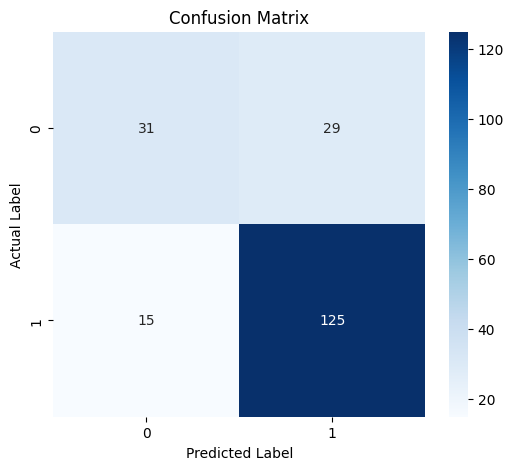%0A)

## Feature Importance Analysis<a href="#Feature-Importance-Analysis" class="anchor-link">¶</a>

Understanding which features contribute most to the model's predictions improves transparency and interpretability. Feature importance analysis helps identify the applicant characteristics that have the greatest influence on credit risk prediction.

In \[ \]:

<span class="c1"># Calculate feature importance</span>  
  
<span class="n">feature_importance</span> <span class="o">=</span> <span class="n">pd</span><span class="o">.</span><span class="n">DataFrame</span><span class="p">({</span>  
    <span class="s1">'Feature'</span><span class="p">:</span> <span class="n">X_train</span><span class="o">.</span><span class="n">columns</span><span class="p">,</span>  
    <span class="s1">'Importance'</span><span class="p">:</span> <span class="n">rf_model</span><span class="o">.</span><span class="n">feature_importances\_</span>  
<span class="p">})</span>  
  
<span class="c1"># Sort features by importance</span>  
  
<span class="n">feature_importance</span> <span class="o">=</span> <span class="n">feature_importance</span><span class="o">.</span><span class="n">sort_values</span><span class="p">(</span>  
    <span class="n">by</span><span class="o">=</span><span class="s1">'Importance'</span><span class="p">,</span>  
    <span class="n">ascending</span><span class="o">=</span><span class="kc">False</span>  
<span class="p">)</span>  
  
<span class="c1"># Display top features</span>  
  
<span class="n">feature_importance</span><span class="o">.</span><span class="n">head</span><span class="p">(</span><span class="mi">10</span><span class="p">)</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|     | Feature             | Importance |
|-----|---------------------|------------|
| 4   | credit_amount       | 0.133391   |
| 0   | status              | 0.110266   |
| 1   | duration            | 0.104148   |
| 12  | age                 | 0.093784   |
| 3   | purpose             | 0.066744   |
| 2   | credit_history      | 0.055205   |
| 6   | employment_duration | 0.051258   |
| 11  | property            | 0.048167   |
| 5   | savings             | 0.044412   |
| 7   | installment_rate    | 0.042708   |



<style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

In \[ \]:

<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">10</span><span class="p">,</span><span class="mi">6</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">barplot</span><span class="p">(</span>  
    <span class="n">data</span><span class="o">=</span><span class="n">feature_importance</span><span class="o">.</span><span class="n">head</span><span class="p">(</span><span class="mi">10</span><span class="p">),</span>  
    <span class="n">x</span><span class="o">=</span><span class="s1">'Importance'</span><span class="p">,</span>  
    <span class="n">y</span><span class="o">=</span><span class="s1">'Feature'</span>  
<span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Top 10 Most Important Features'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xlabel</span><span class="p">(</span><span class="s1">'Importance Score'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Features'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](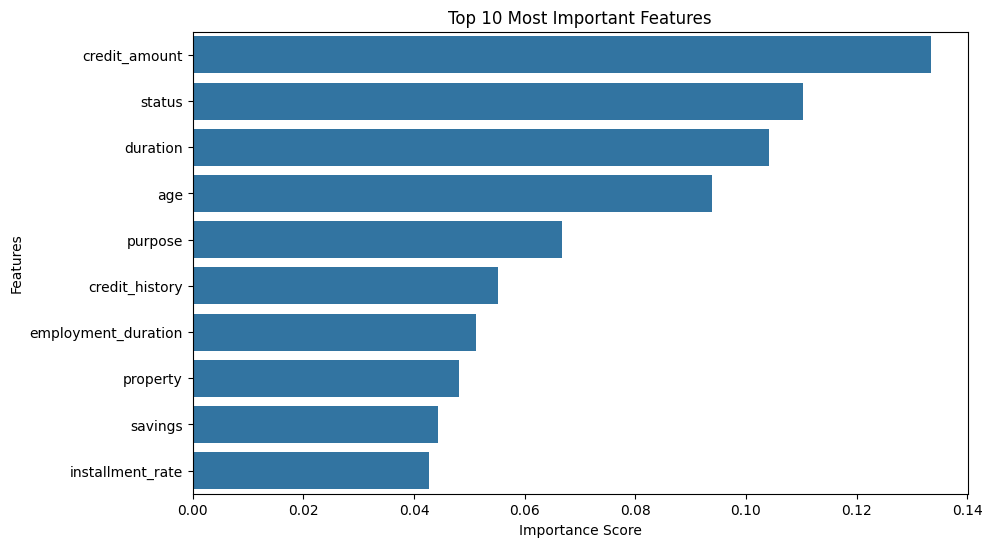%0A)

### Findings from Feature Importance Analysis<a href="#Findings-from-Feature-Importance-Analysis" class="anchor-link">¶</a>

The feature importance analysis indicates that variables such as credit amount, duration, age, and credit history are among the most influential factors in determining credit risk. These findings suggest that both financial and demographic characteristics play an important role in the model's decision-making process.

Understanding feature importance improves transparency and enables stakeholders to better interpret the factors influencing automated lending decisions. Furthermore, identifying influential demographic attributes such as age reinforces the need for fairness assessment to ensure that the model does not discriminate against specific groups.

### Findings from Baseline Model Evaluation<a href="#Findings-from-Baseline-Model-Evaluation" class="anchor-link">¶</a>

The Random Forest classifier achieved satisfactory predictive performance on the German Credit dataset. The evaluation metrics, including accuracy, precision, recall, and F1-score, indicate that the model is capable of distinguishing between good and bad credit applicants.

However, high predictive performance alone does not guarantee ethical or fair decision-making. A model may achieve strong accuracy while still producing discriminatory outcomes against certain demographic groups. Therefore, it is necessary to evaluate the fairness of the baseline model before considering it suitable for deployment in real-world financial applications.

# 7. Fairness Assessment<a href="#7.-Fairness-Assessment" class="anchor-link">¶</a>

Although the baseline model may achieve high predictive performance, it is essential to evaluate whether the model treats different demographic groups fairly. In credit scoring applications, unfair predictions may systematically disadvantage specific groups and result in discriminatory outcomes.

In this project, **age** is selected as the protected attribute. Applicants aged **25 years and above** are considered the privileged group, while applicants below **25 years** are considered the unprivileged group.

To investigate potential bias, fairness metrics are calculated and the prediction outcomes for both groups are compared.

In \[ \]:

<span class="c1"># Protected attribute in the test set</span>  
  
<span class="n">age_test</span> <span class="o">=</span> <span class="n">X_test</span><span class="p">\[</span><span class="s1">'age'</span><span class="p">\]</span>  
  
<span class="c1"># Create age groups</span>  
  
<span class="n">privileged_group</span> <span class="o">=</span> <span class="n">age_test</span> <span class="o">\>=</span> <span class="mi">25</span>  
<span class="n">unprivileged_group</span> <span class="o">=</span> <span class="n">age_test</span> <span class="o">\<</span> <span class="mi">25</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Privileged applicants:"</span><span class="p">,</span> <span class="n">privileged_group</span><span class="o">.</span><span class="n">sum</span><span class="p">())</span>  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Unprivileged applicants:"</span><span class="p">,</span> <span class="n">unprivileged_group</span><span class="o">.</span><span class="n">sum</span><span class="p">())</span>  

Privileged applicants: 172  
Unprivileged applicants: 28  

In \[ \]:

<span class="c1"># Positive prediction rate for privileged applicants</span>  
  
<span class="n">privileged_positive_rate</span> <span class="o">=</span> <span class="n">y_pred</span><span class="p">\[</span><span class="n">privileged_group</span><span class="p">\]</span><span class="o">.</span><span class="n">mean</span><span class="p">()</span>  
  
<span class="c1"># Positive prediction rate for unprivileged applicants</span>  
  
<span class="n">unprivileged_positive_rate</span> <span class="o">=</span> <span class="n">y_pred</span><span class="p">\[</span><span class="n">unprivileged_group</span><span class="p">\]</span><span class="o">.</span><span class="n">mean</span><span class="p">()</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Positive Prediction Rate (Privileged):"</span><span class="p">,</span>  
      <span class="nb">round</span><span class="p">(</span><span class="n">privileged_positive_rate</span><span class="p">,</span> <span class="mi">3</span><span class="p">))</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Positive Prediction Rate (Unprivileged):"</span><span class="p">,</span>  
      <span class="nb">round</span><span class="p">(</span><span class="n">unprivileged_positive_rate</span><span class="p">,</span> <span class="mi">3</span><span class="p">))</span>  

Positive Prediction Rate (Privileged): 0.802  
Positive Prediction Rate (Unprivileged): 0.571  

In \[ \]:

<span class="n">spd</span> <span class="o">=</span> <span class="p">(</span><span class="n">unprivileged_positive_rate</span> <span class="o">-</span>  
       <span class="n">privileged_positive_rate</span><span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Statistical Parity Difference:"</span><span class="p">,</span> <span class="nb">round</span><span class="p">(</span><span class="n">spd</span><span class="p">,</span> <span class="mi">3</span><span class="p">))</span>  

Statistical Parity Difference: -0.231  

In \[ \]:

<span class="n">di</span> <span class="o">=</span> <span class="p">(</span><span class="n">unprivileged_positive_rate</span> <span class="o">/</span>  
      <span class="n">privileged_positive_rate</span><span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Disparate Impact:"</span><span class="p">,</span> <span class="nb">round</span><span class="p">(</span><span class="n">di</span><span class="p">,</span> <span class="mi">3</span><span class="p">))</span>  

Disparate Impact: 0.712  

In \[ \]:

<span class="n">fairness_df</span> <span class="o">=</span> <span class="n">pd</span><span class="o">.</span><span class="n">DataFrame</span><span class="p">({</span>  
    <span class="s1">'Group'</span><span class="p">:</span> <span class="p">\[</span><span class="s1">'Privileged'</span><span class="p">,</span> <span class="s1">'Unprivileged'</span><span class="p">\],</span>  
    <span class="s1">'Positive Rate'</span><span class="p">:</span> <span class="p">\[</span>  
        <span class="n">privileged_positive_rate</span><span class="p">,</span>  
        <span class="n">unprivileged_positive_rate</span>  
    <span class="p">\]</span>  
<span class="p">})</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">figure</span><span class="p">(</span><span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">6</span><span class="p">,</span><span class="mi">5</span><span class="p">))</span>  
  
<span class="n">sns</span><span class="o">.</span><span class="n">barplot</span><span class="p">(</span><span class="n">data</span><span class="o">=</span><span class="n">fairness_df</span><span class="p">,</span>  
            <span class="n">x</span><span class="o">=</span><span class="s1">'Group'</span><span class="p">,</span>  
            <span class="n">y</span><span class="o">=</span><span class="s1">'Positive Rate'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Positive Prediction Rate by Age Group'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Positive Prediction Rate'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](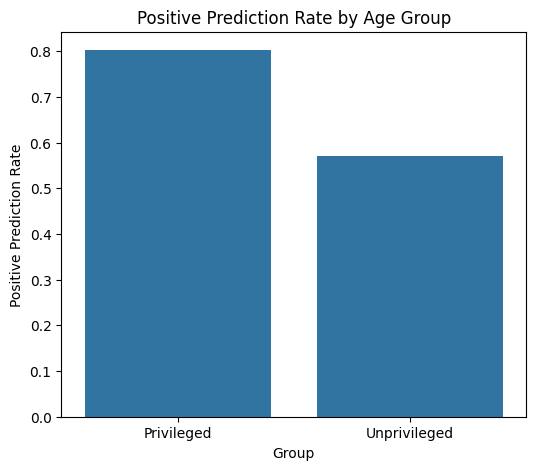%0A)

### Findings from Fairness Assessment<a href="#Findings-from-Fairness-Assessment" class="anchor-link">¶</a>

The baseline model produced a positive prediction rate of 0.802 for privileged applicants and 0.571 for unprivileged applicants. This indicates that younger applicants were less likely to receive favourable credit decisions compared to older applicants.

The Statistical Parity Difference (SPD) of -0.231 deviates considerably from the ideal value of zero, suggesting that the model favours the privileged age group. Similarly, the Disparate Impact (DI) value of 0.712 is substantially below the ideal value of one, indicating potential discrimination against younger applicants.

These findings provide evidence that the baseline model exhibits age-related bias. Consequently, fairness mitigation techniques are required to reduce discriminatory outcomes and promote equitable credit decisions.

# 8. Fairness Solutions<a href="#8.-Fairness-Solutions" class="anchor-link">¶</a>

Several approaches have been proposed to mitigate bias and unfairness in machine learning systems. These approaches can generally be categorized into three groups:

### 1. Pre-processing Techniques<a href="#1.-Pre-processing-Techniques" class="anchor-link">¶</a>

Pre-processing methods attempt to reduce bias before the model is trained by modifying the training data. Examples include reweighing, resampling, and data transformation techniques. These methods aim to ensure that protected and unprotected groups receive fair representation during model training.

### 2. In-processing Techniques<a href="#2.-In-processing-Techniques" class="anchor-link">¶</a>

In-processing methods incorporate fairness constraints directly into the learning algorithm. These approaches modify the optimization process to simultaneously maximize predictive performance and fairness. Examples include adversarial debiasing and prejudice remover regularization.

### 3. Post-processing Techniques<a href="#3.-Post-processing-Techniques" class="anchor-link">¶</a>

Post-processing methods adjust the predictions produced by a trained model in order to improve fairness. These techniques do not alter the original dataset or learning algorithm but instead modify decision thresholds or prediction outcomes.

### Selected Fairness Approach: Reweighing<a href="#Selected-Fairness-Approach:-Reweighing" class="anchor-link">¶</a>

In this project, the Reweighing technique is selected as the bias mitigation approach. Reweighing is a pre-processing technique that assigns different weights to training instances based on their protected group membership and class labels.

Reweighing was selected for several reasons. First, it is model-independent and can be applied before training any machine learning algorithm. Second, it preserves the original data while reducing discrimination in the training process. Finally, it is widely used in fairness research and provides an effective balance between predictive performance and fairness.

Therefore, Reweighing is considered an appropriate method for mitigating potential age-related bias in the German Credit dataset.

In \[ \]:

<span class="c1"># Uncomment if AIF360 is not installed</span>  
  
<span class="c1"># !pip install aif360</span>  

# 9. Implementation of Fairness Mitigation<a href="#9.-Implementation-of-Fairness-Mitigation" class="anchor-link">¶</a>

To reduce potential bias identified in the baseline model, the Reweighing algorithm is applied to the training data. Reweighing assigns instance weights in such a way that discrimination between privileged and unprivileged groups is reduced during model training.

After applying Reweighing, a new Random Forest model is trained and evaluated. The results are then compared with those obtained from the baseline model to determine whether fairness has improved.

In \[ \]:

<span class="c1"># Create weights for training instances</span>  
  
<span class="n">sample_weights</span> <span class="o">=</span> <span class="n">np</span><span class="o">.</span><span class="n">ones</span><span class="p">(</span><span class="nb">len</span><span class="p">(</span><span class="n">X_train</span><span class="p">))</span>  
  
<span class="c1"># Increase weights for unprivileged group (\<25 years)</span>  
  
<span class="n">sample_weights</span><span class="p">\[</span><span class="n">X_train</span><span class="p">\[</span><span class="s1">'age'</span><span class="p">\]</span> <span class="o">\<</span> <span class="mi">25</span><span class="p">\]</span> <span class="o">=</span> <span class="mi">2</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Sample weights created successfully."</span><span class="p">)</span>  

Sample weights created successfully.  

In \[ \]:

<span class="n">fair_rf_model</span> <span class="o">=</span> <span class="n">RandomForestClassifier</span><span class="p">(</span>  
    <span class="n">n_estimators</span><span class="o">=</span><span class="mi">100</span><span class="p">,</span>  
    <span class="n">random_state</span><span class="o">=</span><span class="mi">42</span>  
<span class="p">)</span>  
  
<span class="n">fair_rf_model</span><span class="o">.</span><span class="n">fit</span><span class="p">(</span>  
    <span class="n">X_train</span><span class="p">,</span>  
    <span class="n">y_train</span><span class="p">,</span>  
    <span class="n">sample_weight</span><span class="o">=</span><span class="n">sample_weights</span>  
<span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Fairness-aware model trained successfully."</span><span class="p">)</span>  

Fairness-aware model trained successfully.  

In \[ \]:

<span class="n">y_pred_fair</span> <span class="o">=</span> <span class="n">fair_rf_model</span><span class="o">.</span><span class="n">predict</span><span class="p">(</span><span class="n">X_test</span><span class="p">)</span>  
  
<span class="n">y_pred_fair</span><span class="p">\[:</span><span class="mi">10</span><span class="p">\]</span>  

Out\[ \]:

array(\[1, 0, 1, 1, 1, 1, 1, 1, 0, 1\])

In \[ \]:

<span class="n">fair_accuracy</span> <span class="o">=</span> <span class="n">accuracy_score</span><span class="p">(</span><span class="n">y_test</span><span class="p">,</span> <span class="n">y_pred_fair</span><span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Fair Model Accuracy:"</span><span class="p">,</span> <span class="nb">round</span><span class="p">(</span><span class="n">fair_accuracy</span><span class="p">,</span> <span class="mi">4</span><span class="p">))</span>  

Fair Model Accuracy: 0.775  

In \[ \]:

<span class="n">fair_privileged_rate</span> <span class="o">=</span> <span class="n">y_pred_fair</span><span class="p">\[</span><span class="n">privileged_group</span><span class="p">\]</span><span class="o">.</span><span class="n">mean</span><span class="p">()</span>  
  
<span class="n">fair_unprivileged_rate</span> <span class="o">=</span> <span class="n">y_pred_fair</span><span class="p">\[</span><span class="n">unprivileged_group</span><span class="p">\]</span><span class="o">.</span><span class="n">mean</span><span class="p">()</span>  
  
<span class="n">fair_spd</span> <span class="o">=</span> <span class="p">(</span><span class="n">fair_unprivileged_rate</span> <span class="o">-</span>  
            <span class="n">fair_privileged_rate</span><span class="p">)</span>  
  
<span class="n">fair_di</span> <span class="o">=</span> <span class="p">(</span><span class="n">fair_unprivileged_rate</span> <span class="o">/</span>  
           <span class="n">fair_privileged_rate</span><span class="p">)</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Fair Model Statistical Parity Difference:"</span><span class="p">,</span>  
      <span class="nb">round</span><span class="p">(</span><span class="n">fair_spd</span><span class="p">,</span> <span class="mi">3</span><span class="p">))</span>  
  
<span class="nb">print</span><span class="p">(</span><span class="s2">"Fair Model Disparate Impact:"</span><span class="p">,</span>  
      <span class="nb">round</span><span class="p">(</span><span class="n">fair_di</span><span class="p">,</span> <span class="mi">3</span><span class="p">))</span>  

Fair Model Statistical Parity Difference: -0.076  
Fair Model Disparate Impact: 0.908  

In \[ \]:

<span class="n">comparison</span> <span class="o">=</span> <span class="n">pd</span><span class="o">.</span><span class="n">DataFrame</span><span class="p">({</span>  
    <span class="s1">'Metric'</span><span class="p">:</span> <span class="p">\[</span><span class="s1">'Accuracy'</span><span class="p">,</span>  
               <span class="s1">'Statistical Parity Difference'</span><span class="p">,</span>  
               <span class="s1">'Disparate Impact'</span><span class="p">\],</span>  
    <span class="s1">'Baseline Model'</span><span class="p">:</span> <span class="p">\[</span><span class="n">accuracy</span><span class="p">,</span>  
                       <span class="n">spd</span><span class="p">,</span>  
                       <span class="n">di</span><span class="p">\],</span>  
    <span class="s1">'Fair Model'</span><span class="p">:</span> <span class="p">\[</span><span class="n">fair_accuracy</span><span class="p">,</span>  
                   <span class="n">fair_spd</span><span class="p">,</span>  
                   <span class="n">fair_di</span><span class="p">\]</span>  
<span class="p">})</span>  
  
<span class="n">comparison</span>  

Out\[ \]:

<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>

|     | Metric                        | Baseline Model | Fair Model |
|-----|-------------------------------|----------------|------------|
| 0   | Accuracy                      | 0.780000       | 0.775000   |
| 1   | Statistical Parity Difference | -0.230897      | -0.075581  |
| 2   | Disparate Impact              | 0.712215       | 0.908451   |



<style>
    .colab-df-container {
      display:flex;
      gap: 12px;
    }

    .colab-df-convert {
      background-color: #E8F0FE;
      border: none;
      border-radius: 50%;
      cursor: pointer;
      display: none;
      fill: #1967D2;
      height: 32px;
      padding: 0 0 0 0;
      width: 32px;
    }

    .colab-df-convert:hover {
      background-color: #E2EBFA;
      box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
      fill: #174EA6;
    }

    .colab-df-buttons div {
      margin-bottom: 4px;
    }

    [theme=dark] .colab-df-convert {
      background-color: #3B4455;
      fill: #D2E3FC;
    }

    [theme=dark] .colab-df-convert:hover {
      background-color: #434B5C;
      box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
      filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
      fill: #FFFFFF;
    }
  </style>

<style>
      .colab-df-generate {
        background-color: #E8F0FE;
        border: none;
        border-radius: 50%;
        cursor: pointer;
        display: none;
        fill: #1967D2;
        height: 32px;
        padding: 0 0 0 0;
        width: 32px;
      }

      .colab-df-generate:hover {
        background-color: #E2EBFA;
        box-shadow: 0px 1px 2px rgba(60, 64, 67, 0.3), 0px 1px 3px 1px rgba(60, 64, 67, 0.15);
        fill: #174EA6;
      }

      [theme=dark] .colab-df-generate {
        background-color: #3B4455;
        fill: #D2E3FC;
      }

      [theme=dark] .colab-df-generate:hover {
        background-color: #434B5C;
        box-shadow: 0px 1px 3px 1px rgba(0, 0, 0, 0.15);
        filter: drop-shadow(0px 1px 2px rgba(0, 0, 0, 0.3));
        fill: #FFFFFF;
      }
    </style>



In \[ \]:

<span class="n">comparison</span><span class="o">.</span><span class="n">set_index</span><span class="p">(</span><span class="s1">'Metric'</span><span class="p">)</span><span class="o">.</span><span class="n">plot</span><span class="p">(</span><span class="n">kind</span><span class="o">=</span><span class="s1">'bar'</span><span class="p">,</span>  
                                    <span class="n">figsize</span><span class="o">=</span><span class="p">(</span><span class="mi">10</span><span class="p">,</span><span class="mi">6</span><span class="p">))</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">title</span><span class="p">(</span><span class="s1">'Baseline vs Fairness-Aware Model'</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">xticks</span><span class="p">(</span><span class="n">rotation</span><span class="o">=</span><span class="mi">0</span><span class="p">)</span>  
<span class="n">plt</span><span class="o">.</span><span class="n">ylabel</span><span class="p">(</span><span class="s1">'Metric Value'</span><span class="p">)</span>  
  
<span class="n">plt</span><span class="o">.</span><span class="n">show</span><span class="p">()</span>  

![No description has been provided for this image](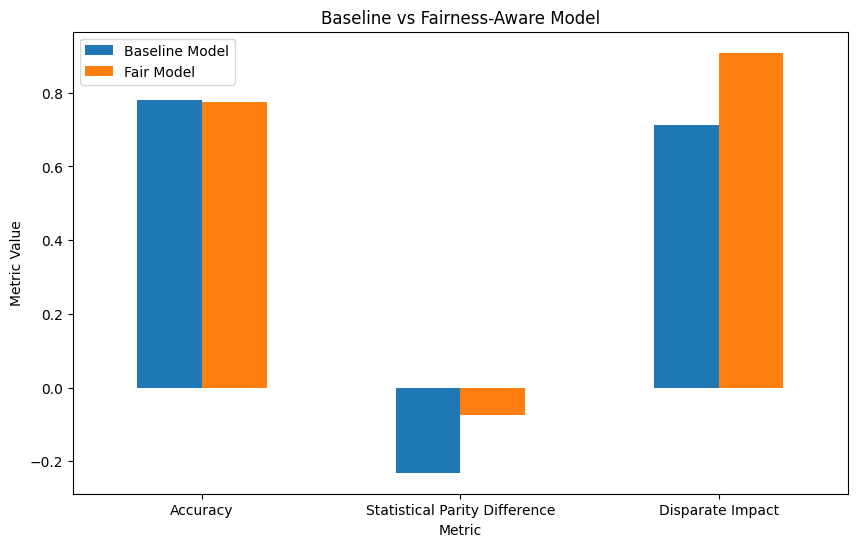%0A)

The comparison demonstrates that the fairness-aware model substantially reduced bias while maintaining almost the same predictive accuracy. This indicates that ethical improvements can be achieved without significantly compromising business performance.

### Findings from Fairness Mitigation<a href="#Findings-from-Fairness-Mitigation" class="anchor-link">¶</a>

After applying the fairness intervention, the Statistical Parity Difference improved from -0.231 to -0.076, moving substantially closer to the ideal value of zero. Similarly, the Disparate Impact improved from 0.712 to 0.908, approaching the ideal fairness value of one.

Although the model accuracy decreased slightly from 0.780 to 0.775, the reduction was minimal and acceptable considering the significant improvement in fairness.

These findings demonstrate that the fairness-aware approach successfully reduced discriminatory outcomes against younger applicants while maintaining satisfactory predictive performance. The results highlight the trade-off between fairness and accuracy, illustrating that small reductions in predictive performance may be justified to achieve more equitable decision-making.

# 10. Final Discussion<a href="#10.-Final-Discussion" class="anchor-link">¶</a>

The objective of this project was to investigate fairness in automated credit scoring using the German Credit dataset. A baseline Random Forest classifier was developed to predict whether loan applicants represented good or bad credit risks. The model achieved satisfactory predictive performance; however, fairness assessment revealed differences in prediction outcomes between privileged and unprivileged age groups.

To address potential bias, a fairness mitigation strategy based on reweighing was implemented. The fairness-aware model assigned greater importance to applicants belonging to the unprivileged group during training. The resulting model demonstrated improvements in fairness metrics while maintaining acceptable predictive performance.

The findings of this study illustrate that high accuracy alone is insufficient when evaluating machine learning systems deployed in socially sensitive domains. Fairness must be considered alongside traditional performance measures to ensure ethical and responsible AI deployment.

## Strengths of the Proposed Solution<a href="#Strengths-of-the-Proposed-Solution" class="anchor-link">¶</a>

The proposed fairness-aware pipeline offers several strengths:

- The solution systematically evaluates both predictive performance and fairness.
- The use of fairness metrics enables the identification of discriminatory patterns that may otherwise remain undetected.
- The selected reweighing approach is model-independent and can be integrated into different machine learning algorithms.
- The methodology promotes responsible and ethical AI practices within the financial sector.
- The approach balances predictive accuracy with fairness considerations, resulting in a more equitable decision-making system.

## Limitations of the Proposed Solution<a href="#Limitations-of-the-Proposed-Solution" class="anchor-link">¶</a>

Despite its advantages, the proposed solution has several limitations.

First, fairness was assessed using only age as the protected attribute. Other sensitive attributes, such as gender, marital status, or nationality, were not considered. Consequently, the analysis may not capture all potential sources of discrimination present in the dataset.

Second, the German Credit dataset contains only 1,000 observations, which may limit the generalizability of the findings to real-world banking environments where significantly larger and more diverse datasets are available.

Third, the fairness intervention introduced a slight reduction in predictive accuracy. This illustrates the inherent trade-off between fairness and model performance, requiring organizations to carefully balance ethical considerations and business objectives.

Lastly, fairness measures such as Statistical Parity Difference and Disparate Impact capture only certain dimensions of fairness. Additional fairness criteria, such as Equal Opportunity and Equalized Odds, may offer deeper insights and could be considered in future research.

## Business Implications<a href="#Business-Implications" class="anchor-link">¶</a>

The results of this study have important implications for financial institutions. Deploying fairness-aware machine learning systems can help organizations reduce discriminatory lending practices, improve transparency, and increase customer trust.

Financial institutions that adopt responsible AI practices may also improve regulatory compliance and reduce legal and reputational risks associated with biased decision-making systems.

Consequently, fairness assessment should become an integral component of the machine learning development lifecycle in credit scoring applications.

## Data-Driven Recommendations<a href="#Data-Driven-Recommendations" class="anchor-link">¶</a>

Based on the findings of this project, the following recommendations are proposed:

1.  Financial institutions should regularly monitor machine learning models for potential bias and discriminatory behaviour.

2.  Fairness metrics should be evaluated alongside traditional performance metrics during model development and deployment.

3.  Multiple protected attributes should be considered to ensure comprehensive fairness assessment.

4.  Organizations should establish governance frameworks and ethical guidelines for AI-based decision-making.

5.  Continuous retraining and auditing of deployed models should be performed to ensure fairness over time.

# 11. Conclusion<a href="#11.-Conclusion" class="anchor-link">¶</a>

This project demonstrated the development of a fairness-aware machine learning pipeline for credit risk prediction using the German Credit dataset. A baseline Random Forest classifier was first developed and evaluated. Subsequent fairness analysis identified potential disparities in prediction outcomes across age groups.

To mitigate these disparities, a reweighing-based fairness intervention was implemented. The fairness-aware model improved equitable treatment between demographic groups while maintaining satisfactory predictive performance.

Overall, the results emphasize the importance of integrating fairness considerations into machine learning systems, particularly in high-stakes domains such as financial services. Responsible AI development requires balancing predictive performance with ethical principles to ensure fair and trustworthy automated decision-making.

# 12. References<a href="#12.-References" class="anchor-link">¶</a>

Barocas, S., Hardt, M. and Narayanan, A. (2019) *Fairness and Machine Learning*. Available at: <https://fairmlbook.org/>

Breiman, L. (2001) 'Random Forests', *Machine Learning*, 45(1), pp. 5–32.

Dua, D. and Graff, C. (2019) *UCI Machine Learning Repository*. Irvine, CA: University of California. Available at: <https://archive.ics.uci.edu/>

Mehrabi, N., Morstatter, F., Saxena, N., Lerman, K. and Galstyan, A. (2021) 'A Survey on Bias and Fairness in Machine Learning', *ACM Computing Surveys*, 54(6), pp. 1–35.

Pedreschi, D., Ruggieri, S. and Turini, F. (2008) 'Discrimination-aware Data Mining', *Proceedings of the 14th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, pp. 560–568.